# 3. Imóvel, fundos imobiliários ou renda fixa?

Antes de simular a decisão de comprar ou alugar, vale olhar para os três destinos possíveis do dinheiro como
investimentos, lado a lado:

- **Imóvel físico**: valorização do m² mais o aluguel recebido (FipeZAP).
- **Fundos imobiliários**: o **IFIX**, índice da B3 que já considera os rendimentos reinvestidos.
- **Renda fixa**: o **CDI**, referência das aplicações pós-fixadas.

O período é o do IFIX, que começa no último pregão de 2010.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from comprar_ou_alugar import analise, cenarios, estilo
from comprar_ou_alugar.caminhos import TRATADOS
from comprar_ou_alugar.estilo import br, pct

estilo.aplicar()

cidades = pd.read_parquet(TRATADOS / "cidades.parquet")
mensal = pd.read_parquet(TRATADOS / "mensal.parquet")

TRES_CIDADES = ["São Paulo", "Rio de Janeiro", "Belo Horizonte"]

# Quanto do aluguel bruto sobra para o dono depois de vacância, administração,
# manutenção e imposto. É uma premissa, não um dado: veja a seção "bruto × líquido".
ALUGUEL_LIQUIDO = 0.70


def retornos_mensais(cidade: str) -> tuple[pd.DataFrame, pd.Series]:
    """Variações mensais de cada investimento e a inflação, nos meses em que todos têm dado."""
    serie = cenarios.serie_da_cidade(cidades, mensal, cidade)
    retornos = pd.DataFrame(
        {
            "Imóvel": analise.retorno_total_do_imovel(serie, ALUGUEL_LIQUIDO),
            "FIIs (IFIX)": serie["ifix_var_mes"],
            "CDI": serie["cdi_var_mes"],
        }
    ).dropna()
    retornos = retornos[serie["ipca_var_mes"].reindex(retornos.index).notna()]
    return retornos, serie["ipca_var_mes"].reindex(retornos.index)

## Quinze anos em um gráfico

R\$ 100 aplicados em dezembro de 2010, já descontada a inflação. O imóvel é um apartamento em São Paulo alugado,
com 70% do aluguel bruto chegando ao bolso do dono.

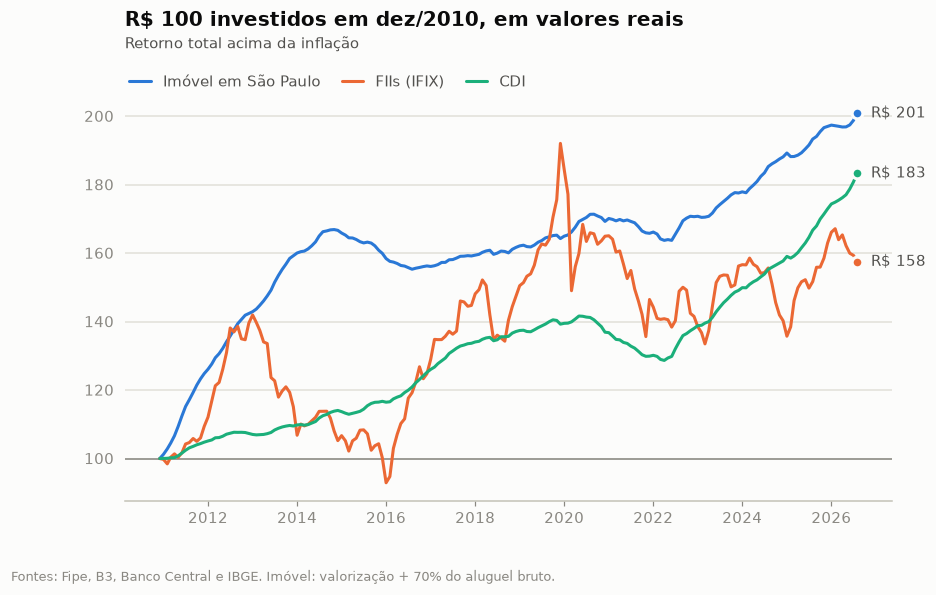

In [2]:
retornos, inflacao = retornos_mensais("São Paulo")
acumulado_real = analise.indice(analise.em_termos_reais(retornos, inflacao))
acumulado_real.loc[retornos.index[0] - pd.DateOffset(months=1)] = 100
acumulado_real = acumulado_real.sort_index()

fig, ax = plt.subplots()
for ativo in retornos:
    ax.plot(
        acumulado_real[ativo], color=estilo.CORES_ATIVOS[ativo], label=ativo.replace("Imóvel", "Imóvel em São Paulo")
    )

estilo.titulo(ax, "R$ 100 investidos em dez/2010, em valores reais", "Retorno total acima da inflação", legenda=True)
estilo.linha_de_base(ax, 100)
estilo.rotular_fins(ax, lambda v: f"R$ {br(v)}")
estilo.fonte(fig, "Fontes: Fipe, B3, Banco Central e IBGE. Imóvel: valorização + 70% do aluguel bruto.")
plt.show()

Três coisas chamam a atenção:

1. **Os FIIs ficaram em último**, atrás até do CDI. O período inclui dois tombos fortes (2013 a 2015 e a pandemia)
   e termina com juros altos, que derrubam o preço das cotas.
2. **A linha do imóvel é lisa demais para ser verdade.** Ela vem de preços de anúncio, que mudam devagar e não
   registram o desconto que o vendedor aceita na hora de fechar. O risco existe, só não aparece nesta medida.
3. **O CDI foi difícil de bater.** O Brasil pagou juro real alto em quase todo o período.

A tabela a seguir resume retorno e risco nas três cidades.

In [3]:
partes = {}
for cidade in TRES_CIDADES:
    retornos, inflacao = retornos_mensais(cidade)
    parte = analise.resumo(retornos, inflacao)
    parte.insert(0, "período", f"{retornos.index[0]:%m/%Y} a {retornos.index[-1]:%m/%Y}")
    partes[cidade] = parte

resumo = pd.concat(partes, names=["cidade", "investimento"])
# No Rio o período é o mesmo de São Paulo: FIIs e CDI seriam linhas repetidas.
resumo = resumo.drop(index=[("Rio de Janeiro", "FIIs (IFIX)"), ("Rio de Janeiro", "CDI")])
colunas = {
    "retorno_aa": "retorno ao ano",
    "retorno_real_aa": "retorno real ao ano",
    "volatilidade_aa": "volatilidade ao ano",
    "maior_queda_real": "maior queda real",
    "meses_negativos": "meses no negativo",
}
resumo[list(colunas)] = resumo[list(colunas)].map(lambda v: pct(v, 1))
resumo[["período", *colunas]].rename(columns=colunas)

período retorno ao ano  \
cidade         investimento                                     
São Paulo      Imóvel        01/2011 a 08/2026          10,5%   
               FIIs (IFIX)   01/2011 a 08/2026           8,8%   
               CDI           01/2011 a 08/2026           9,9%   
Rio de Janeiro Imóvel        01/2011 a 08/2026           7,9%   
Belo Horizonte Imóvel        02/2016 a 08/2026           8,4%   
               FIIs (IFIX)   02/2016 a 08/2026          10,4%   
               CDI           02/2016 a 08/2026           9,6%   

                            retorno real ao ano volatilidade ao ano  \
cidade         investimento                                           
São Paulo      Imóvel                      4,6%                1,9%   
               FIIs (IFIX)                 2,9%               10,3%   
               CDI                         3,9%                1,0%   
Rio de Janeiro Imóvel                      2,1%                2,7%   
Belo Horizonte Imóvel                      3,2%                1,7%   
               FIIs (IFIX)                 5,1%               10,7%   
               CDI                         4,4%                1,1%   

                            maior queda real meses no negativo  
cidade         investimento                                     
São Paulo      Imóvel                  −6,9%              0,0%  
               FIIs (IFIX)            −34,5%             35,1%  
               CDI                     −9,2%              0,0%  
Rio de Janeiro Imóvel                 −29,5%             17,6%  
Belo Horizonte Imóvel                  −7,3%              8,7%  
               FIIs (IFIX)            −30,5%             33,9%  
               CDI                     −9,2%              0,0%

Belo Horizonte tem uma janela mais curta (o aluguel só entra no FipeZAP no fim de 2015), por isso FIIs e CDI
aparecem de novo para essa cidade: os números do mesmo investimento mudam quando o período muda.

## Bruto × líquido

O retorno do imóvel depende muito de quanto do aluguel chega ao dono. A premissa de 70% vem de descontar, do
aluguel bruto: um mês vago a cada dois anos, taxa de administração de 8% a 10%, manutenção e o imposto de renda
sobre aluguéis (até 27,5% na pessoa física). É uma estimativa. A tabela mostra quanto o resultado muda com ela.

In [4]:
retornos_sp, inflacao_sp = retornos_mensais("São Paulo")
serie_sp = cenarios.serie_da_cidade(cidades, mensal, "São Paulo")
anos = len(retornos_sp) / 12

linhas = []
for fracao in (1.0, 0.85, 0.70, 0.55):
    total = analise.retorno_total_do_imovel(serie_sp, fracao).reindex(retornos_sp.index)
    real = (1 + total) / (1 + inflacao_sp) - 1
    linhas.append(
        {
            "aluguel que chega ao dono": pct(fracao),
            "retorno ao ano": pct((1 + total).prod() ** (1 / anos) - 1, 1),
            "retorno real ao ano": pct((1 + real).prod() ** (1 / anos) - 1, 1),
        }
    )
pd.DataFrame(linhas).set_index("aluguel que chega ao dono")

,retorno ao ano,retorno real ao ano
aluguel que chega ao dono,,
100%,"12,3%","6,3%"
85%,"11,4%","5,4%"
70%,"10,5%","4,6%"
55%,"9,6%","3,7%"


## O retorno depende de quando você entra

Uma média de quinze anos esconde muita coisa. O gráfico mostra o retorno real ao ano de **cada janela de cinco
anos**: cada ponto é o resultado de quem entrou cinco anos antes daquela data.

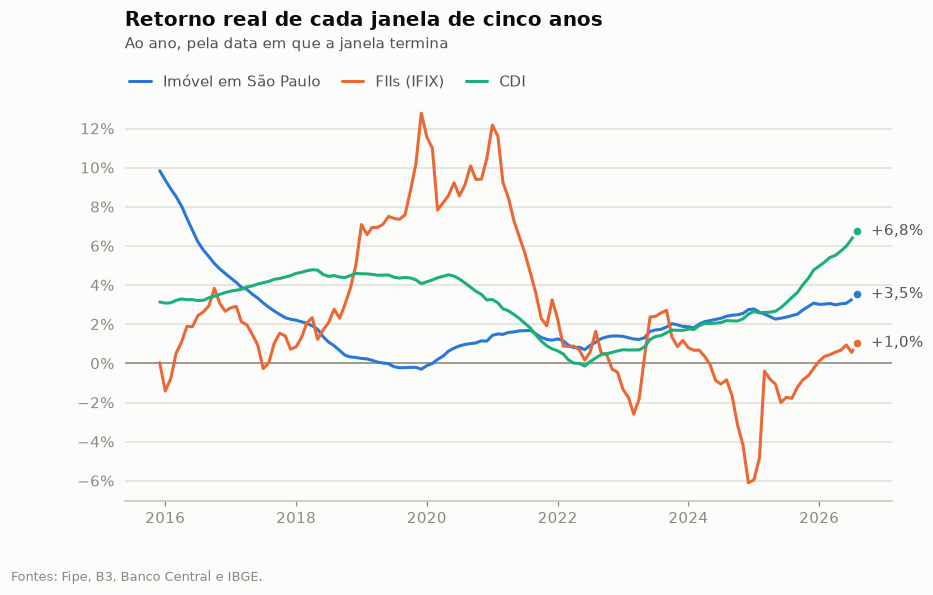

Janelas de cinco anos: 129
  FIIs perderam para a inflação em 22% delas
  FIIs ganharam do CDI em 40%
  FIIs ganharam do imóvel em 40%
  Melhor e pior janela dos FIIs: 12,8% e −6,1% ao ano


In [5]:
retornos, inflacao = retornos_mensais("São Paulo")
janelas = analise.janelas_moveis(analise.em_termos_reais(retornos, inflacao), anos=5)

fig, ax = plt.subplots()
for ativo in janelas:
    ax.plot(janelas[ativo], color=estilo.CORES_ATIVOS[ativo], label=ativo.replace("Imóvel", "Imóvel em São Paulo"))

estilo.titulo(
    ax, "Retorno real de cada janela de cinco anos", "Ao ano, pela data em que a janela termina", legenda=True
)
estilo.linha_de_base(ax)
estilo.eixo_pct(ax.yaxis, passo=0.02)
estilo.rotular_fins(ax, lambda v: pct(v, 1, sinal=True))
estilo.fonte(fig, "Fontes: Fipe, B3, Banco Central e IBGE.")
plt.show()

print(f"Janelas de cinco anos: {len(janelas)}")
print(f"  FIIs perderam para a inflação em {pct((janelas['FIIs (IFIX)'] < 0).mean())} delas")
print(f"  FIIs ganharam do CDI em {pct((janelas['FIIs (IFIX)'] > janelas['CDI']).mean())}")
print(f"  FIIs ganharam do imóvel em {pct((janelas['FIIs (IFIX)'] > janelas['Imóvel']).mean())}")
print(
    f"  Melhor e pior janela dos FIIs: {pct(janelas['FIIs (IFIX)'].max(), 1)} e {pct(janelas['FIIs (IFIX)'].min(), 1)} ao ano"
)

Os FIIs entregaram de −6% a +13% ao ano acima da inflação, conforme a data de entrada. É a maior dispersão dos
três: quem investe em fundos imobiliários precisa aguentar períodos longos ruins.

## De onde vem o retorno dos FIIs

O IFIX soma duas coisas: a variação do preço das cotas e os rendimentos distribuídos todo mês. O informe mensal
que os fundos entregam à CVM permite separar a segunda parte.

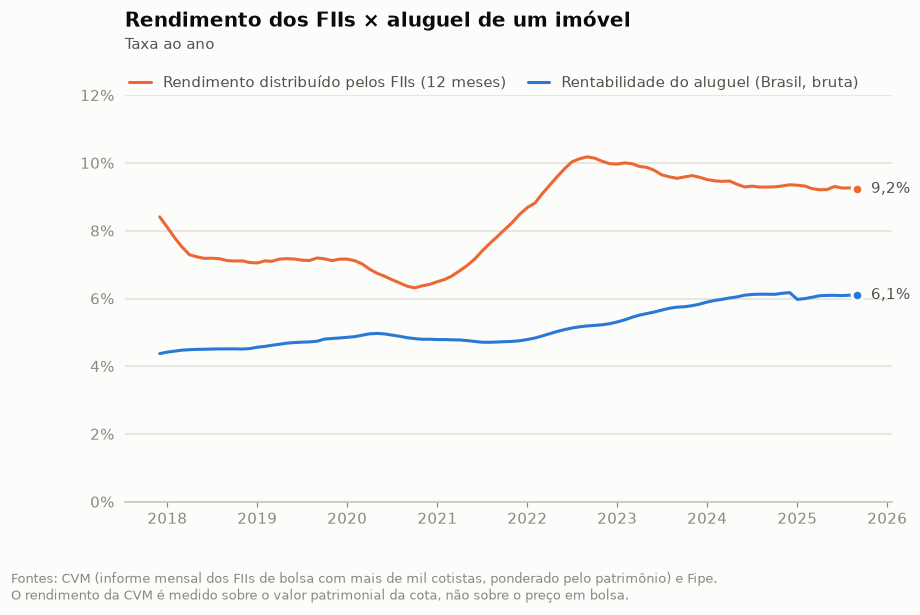

De 01/2017 a 08/2026:
  retorno total do IFIX: 7,6% ao ano
  rendimento distribuído: 8,4% ao ano
  o que sobra para a variação das cotas: −0,8% ao ano


In [6]:
indicadores = mensal.set_index("data")
rendimento_12m = indicadores["fii_dividend_yield_mes"].rolling(12).sum().dropna()
aluguel_nacional = cenarios.serie_da_cidade(cidades, mensal, "Índice FipeZAP")["rentabilidade_aluguel_mes"]
aluguel_12m = analise.anualizar(aluguel_nacional).reindex(rendimento_12m.index)

fig, ax = plt.subplots()
ax.plot(rendimento_12m, color=estilo.LARANJA, label="Rendimento distribuído pelos FIIs (12 meses)")
ax.plot(aluguel_12m, color=estilo.AZUL, label="Rentabilidade do aluguel (Brasil, bruta)")
estilo.titulo(ax, "Rendimento dos FIIs × aluguel de um imóvel", "Taxa ao ano", legenda=True)
estilo.eixo_pct(ax.yaxis)
ax.set_ylim(0, 0.12)
estilo.rotular_fins(ax, lambda v: pct(v, 1))
estilo.fonte(
    fig,
    "Fontes: CVM (informe mensal dos FIIs de bolsa com mais de mil cotistas, ponderado pelo patrimônio) e Fipe.\n"
    "O rendimento da CVM é medido sobre o valor patrimonial da cota, não sobre o preço em bolsa.",
)
plt.show()

periodo = indicadores["fii_dividend_yield_mes"].dropna().index
total_aa = (1 + indicadores.loc[periodo, "ifix_var_mes"]).prod() ** (12 / len(periodo)) - 1
rendimento_aa = indicadores.loc[periodo, "fii_dividend_yield_mes"].mean() * 12
print(f"De {periodo[0]:%m/%Y} a {periodo[-1]:%m/%Y}:")
print(f"  retorno total do IFIX: {pct(total_aa, 1)} ao ano")
print(f"  rendimento distribuído: {pct(rendimento_aa, 1)} ao ano")
print(f"  o que sobra para a variação das cotas: {pct(total_aa - rendimento_aa, 1, sinal=True)} ao ano")

Os fundos distribuem cerca de 8,4% ao ano, mais do que um imóvel rende de aluguel bruto. O retorno total do
IFIX no mesmo período foi menor que isso (7,6%), o que significa que o preço das cotas **caiu** um pouco, perto
de 1% ao ano. Todo o ganho de quem investiu em FIIs veio dos rendimentos mensais, que para a pessoa física são
isentos de imposto de renda.

## O que fica deste notebook

1. **De 2011 a 2026, os FIIs renderam cerca de 2,9% ao ano acima da inflação**, menos que o CDI (3,9%) e menos
   que um apartamento alugado em São Paulo (4,6%, com 70% do aluguel).
2. **O resultado muda com a cidade.** No Rio, onde os preços caíram, o imóvel rendeu 2,1% real: menos que os FIIs.
3. **Os FIIs são o investimento mais arriscado dos três**: volatilidade de 10% ao ano, queda real de 35% no pior
   momento e uma em cada cinco janelas de cinco anos abaixo da inflação.
4. **A comparação é injusta com os FIIs em um ponto**: o risco do imóvel está escondido nos preços de anúncio.
   E é injusta com o imóvel em outro: ninguém compra um "índice" de apartamentos; compra um, com vizinho, reforma
   e inquilino.
5. Nada disso responde ainda à pergunta do projeto. Quem compra para morar **financia**, e quem aluga **investe a
   diferença**. Essa conta está no próximo notebook.